In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import math
import autoroot

m_key_dict = {
        'LSTM': 'module.layers.LSTM.hidden_size',
        'S4': 'module.layers.Layer2.d_model',
        'TCN': 'module.layers.Layer2.channel',
        'Trans_hid_dim': 'module.layers.Layer1.hid_dim',
        'Trans_nhead': 'module.layers.Layer1.nhead'
    }
from plot_config import set_plot_style

font_size = 55
legend_font_size = 35
lw=4
figsize = (12,8)

# Apply consistent styling
set_plot_style(font_family='Times New Roman', font_size=font_size, legend_font_size=legend_font_size, figsize=figsize, palette='Spectral')


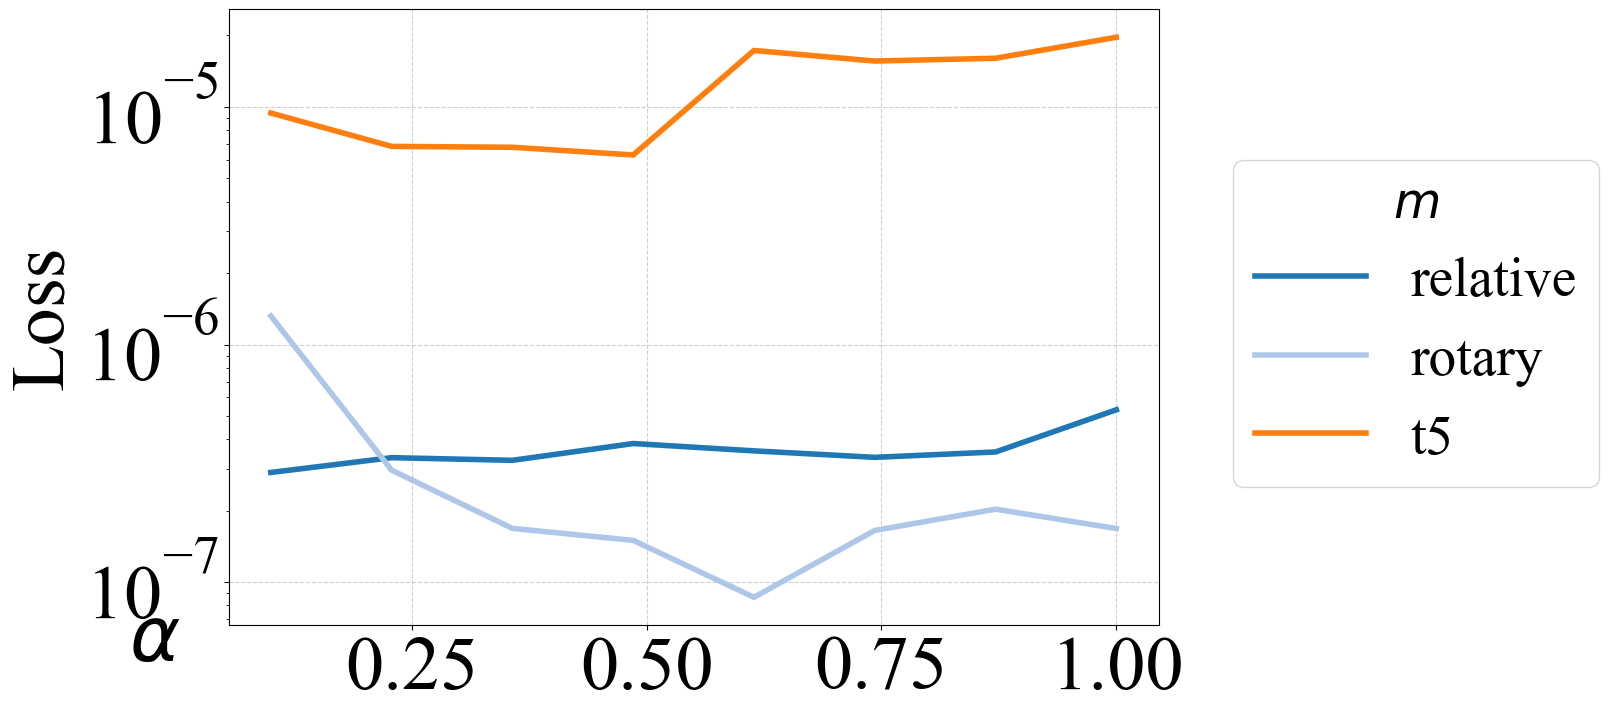

In [2]:
m_key_1 = m_key_dict['Trans_hid_dim']
m_key_2 = m_key_dict['Trans_nhead']
df = pd.read_pickle(f"data/RPETransformer_impulse_step4_data_clean.pkl")
df['m_1'] = df[m_key_1]
df['m_2'] = df[m_key_2]
df['style'] = df['module.layers.Layer1.style']
df['alpha'] = df['data.rho_param.alpha']/df['data.rho_param.alpha'].max()
df_min = df.groupby(['style','alpha'], as_index=False)['train/rLoss1_epoch.min'].min()

fig, ax1 = plt.subplots(figsize=figsize)

# Plot the original lines
palette = sns.color_palette('tab20', n_colors=df_min['style'].nunique())
sns.lineplot(data=df_min, x='alpha', y='train/rLoss1_epoch.min', ax=ax1, palette=palette, hue='style',
              lw=lw)


ax1.set_xlabel(r'$\alpha$')
ax1.xaxis.set_label_coords(-0.08, 0.03)
ax1.set_yscale('log')
ax1.set_ylabel('Loss')
ax1.legend(title=r'$m$',bbox_to_anchor=(1.05, 0.8), loc='upper left')
# ax1.set_title(r'$n_h=4$')
plt.savefig('figs/RPE.pdf', bbox_inches='tight')
